# Trực quan hóa Phổ Tần số 1D (*Radial Power Spectrum*): Ảnh Thật vs. Ảnh AI

Notebook này tận dụng pipeline tiền xử lý chuẩn của đồ án (`CommonProcess` + `FFTPreprocessor`) để vẽ **Biểu đồ Đường 1D (Radial Power Spectrum)** so sánh trực tiếp giữa **Ảnh thật** và **các mô hình AI** trên cùng một hệ trục tọa độ.

### Quy mô dữ liệu sử dụng để vẽ biểu đồ (Tập Validation Known):
* **Tổng số ảnh:** **`5,836` ảnh** (gồm đúng **`1,459` bộ ảnh cùng chủ đề/cảnh vật**, giúp so sánh công bằng).
* **Ảnh thật (`MS_COCO`):** **`1,459` ảnh**.
* **Ảnh AI (`4,377` ảnh):** Chia đều cho 3 mô hình sinh ảnh Known:
  * `Stable Diffusion 2.1`: `1,459` ảnh
  * `Stable Diffusion XL`: `1,459` ảnh
  * `DALL-E 3`: `1,459` ảnh

*(Mặc định `INCLUDE_TEST_UNSEEN = False` để giữ độc lập hoàn toàn cho tập Test trước khi hoàn tất toàn hệ thống; có thể bật `True` sau bước tổng kết cuối để vẽ thêm `Stable Diffusion 3` và `Midjourney V6`.)*

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style đồ thị rõ ràng, dễ đọc cho Slide bảo vệ & Khóa luận
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.28
plt.rcParams["grid.linestyle"] = "--"
plt.rcParams["axes.edgecolor"] = "#bbbbbb"
plt.rcParams["axes.linewidth"] = 0.8

# Tự động dò thư mục gốc dự án DATN
cwd = Path.cwd().resolve()
ROOT_DIR = cwd.parent if cwd.name == "figures" else cwd
if not (ROOT_DIR / "code").exists():
    ROOT_DIR = Path(r"D:\nam_4\DATN")

OUT_DIR = ROOT_DIR / "figures" / "fft"
OUT_DIR.mkdir(parents=True, exist_ok=True)

for p in [
    str(ROOT_DIR / "code" / "system" / "prepare_data"),
    str(ROOT_DIR / "code" / "pre_processing" / "pre_processing_all_and_branchs"),
]:
    if p not in sys.path:
        sys.path.insert(0, p)

from split_dataset import get_split_dataframes
from pre_processing_for_all import CommonProcess
from pre_processing_FFT import FFTPreprocessor

print(f"-> ROOT_DIR: {ROOT_DIR}")
print(f"-> OUT_DIR : {OUT_DIR}")

-> ROOT_DIR: D:\nam_4\DATN
-> OUT_DIR : D:\nam_4\DATN\figures


## 1. Nạp danh sách ảnh & Tính Phổ 2D FFT trung bình cho từng nguồn

Các bước xử lý cho mỗi bức ảnh giống hệt đầu vào của nhánh `FFT.py`:
1. Cắt đúng ô pixel gốc `view_native` (`224 x 224`, không resize để giữ nguyên chi tiết tần số cao).
2. Chuyển sang độ sáng `Luma Y'` và khử độ sáng trung bình nền (`remove_dc=True`).
3. Biến đổi 2D FFT, dịch tâm `0 Hz` vào giữa (`112, 112`) và lấy logarit năng lượng `log(1 + |F|)`.

In [2]:
INCLUDE_TEST_UNSEEN = False

MODEL_ORDER = [
    "MS_COCO",
    "DALL-E_3",
    "Stable_Diffusion_2.1",
    "Stable_Diffusion_XL",
]
if INCLUDE_TEST_UNSEEN:
    MODEL_ORDER += ["Stable_Diffusion_3", "Midjourney_V6"]

DISPLAY_NAMES = {
    "MS_COCO": "Ảnh thật (MS_COCO)",
    "DALL-E_3": "AI — DALL-E 3",
    "Stable_Diffusion_2.1": "AI — Stable Diffusion 2.1",
    "Stable_Diffusion_XL": "AI — Stable Diffusion XL",
    "Stable_Diffusion_3": "AI — Stable Diffusion 3 (Unseen)",
    "Midjourney_V6": "AI — Midjourney V6 (Unseen)",
}

PALETTE = {
    "MS_COCO": "#1b9e77",               # Xanh lá đậm (Chuẩn ảnh thật)
    "DALL-E_3": "#e7298a",              # Hồng đỏ đậm
    "Stable_Diffusion_2.1": "#d95f02",  # Cam đậm
    "Stable_Diffusion_XL": "#7570b3",   # Tím chàm
    "Stable_Diffusion_3": "#66a61e",
    "Midjourney_V6": "#e6ab02",
}

DATASET_ROOT = ROOT_DIR / "dataset" / "Defactify_dataset"
_, val_df, test_df = get_split_dataframes(str(DATASET_ROOT / "metadata.csv"))

if INCLUDE_TEST_UNSEEN:
    unseen_df = test_df[test_df["model_name"].isin(["Stable_Diffusion_3", "Midjourney_V6"])].copy()
    eval_df = pd.concat([val_df, unseen_df], ignore_index=True)
else:
    eval_df = val_df.copy()

n_real = int((eval_df["label_a"] == 0).sum())
n_ai = int((eval_df["label_a"] == 1).sum())
print(f"\n-> Tổng ảnh đưa vào tính phổ 1D: {len(eval_df):,} ảnh ({n_real:,} Ảnh thật | {n_ai:,} Ảnh AI)")
print(eval_df["model_name"].value_counts().reindex(MODEL_ORDER))

common_proc = CommonProcess(mode="eval", crop_size=224, flip_prob=0.0, jpeg_prob=0.0, seed=42)
# normalize=False để giữ đúng thang đo vật lý log(1 + |F|) khi cộng trung bình năng lượng theo bán kính & sai khác 2D
fft_raw_proc = FFTPreprocessor(mode="raw", use_hann=False, remove_dc=True, normalize=False)
# normalize=True (Khử DC & Z-Score) đúng chuẩn Tensor đầu vào trực tiếp của nhánh FFT Residual CNN
fft_zscore_proc = FFTPreprocessor(mode="raw", use_hann=False, remove_dc=True, normalize=True)

sum_raw_2d = {m: np.zeros((224, 224), dtype=np.float64) for m in MODEL_ORDER}
sum_zscore_2d = {m: np.zeros((224, 224), dtype=np.float64) for m in MODEL_ORDER}
counts_by_model = {m: 0 for m in MODEL_ORDER}

n_total = len(eval_df)
for idx in range(n_total):
    row = eval_df.iloc[idx]
    m_name = row["model_name"]
    rel_path = str(row["filepath"]).replace("\\", "/")
    views = common_proc(DATASET_ROOT / rel_path, sample_id=rel_path)

    spec_raw = fft_raw_proc(views).squeeze(0).numpy()        # (224, 224) log(1 + |F|)
    spec_zscore = fft_zscore_proc(views).squeeze(0).numpy()  # (224, 224) Khử DC & Z-Score
    sum_raw_2d[m_name] += spec_raw
    sum_zscore_2d[m_name] += spec_zscore
    counts_by_model[m_name] += 1

    if (idx + 1) % 1500 == 0 or (idx + 1) == n_total:
        print(f"  -> Đã xử lý {idx + 1:,}/{n_total:,} ảnh...")

mean_raw_2d = {m: sum_raw_2d[m] / counts_by_model[m] for m in MODEL_ORDER}
mean_zscore_2d = {m: sum_zscore_2d[m] / counts_by_model[m] for m in MODEL_ORDER}
print("-> Đã tính xong Phổ 2D trung bình (Raw & Z-Score) cho tất cả các nguồn ảnh!")

-> Nạp thành công metadata : 94,272 dòng.
-> Train DataFrame (Known only) : 27,812 ảnh (Real: 6,953, AI: 20,859)
-> Val DataFrame   (Known only) : 5,836 ảnh (Real: 1,459, AI: 4,377)
-> Test DataFrame  (Toàn bộ 6 model): 43,800 ảnh (Real: 7,300, AI: 36,500)

-> Tổng ảnh đưa vào tính phổ 1D: 5,836 ảnh (1,459 Ảnh thật | 4,377 Ảnh AI)
model_name
MS_COCO                 1459
DALL-E_3                1459
Stable_Diffusion_2.1    1459
Stable_Diffusion_XL     1459
Name: count, dtype: int64
  -> Đã xử lý 1,500/5,836 ảnh...
  -> Đã xử lý 3,000/5,836 ảnh...
  -> Đã xử lý 4,500/5,836 ảnh...
  -> Đã xử lý 5,836/5,836 ảnh...
-> Đã tính xong Phổ 2D trung bình cho tất cả các nguồn ảnh!


## 2. Chuyển từ Bản đồ Phổ 2D sang Đường 1D (*Radial Power Spectrum*)

Cách tính rất trực quan:
* Tâm `(112, 112)` của bản đồ phổ là **tần số thấp nhất** (các mảng màu lớn, chuyển biến chậm).
* Đi dần ra mép ngoài (`r = 1 -> 111` pixel) là **tần số cao dần** (các đường nét nhỏ, sợi tóc, hạt nhiễu vi mô).
* Tại mỗi vòng tròn có bán kính $r$, ta lấy **trung bình cộng** độ mạnh của các điểm nằm trên vòng tròn đó $\implies$ thu được **1 đường cong duy nhất** cho mỗi nguồn ảnh để đặt chung lên một đồ thị so sánh.

In [3]:
yy, xx = np.ogrid[:224, :224]
RADIUS_MAP = np.round(np.sqrt((xx - 112.0) ** 2 + (yy - 112.0) ** 2)).astype(np.int32)
MAX_R = 111  # Từ r=1 (sát tâm) đến r=111 (sát mép hình tròn nội tiếp 224x224)

def compute_radial_profile(spec_2d: np.ndarray, max_r: int = MAX_R) -> np.ndarray:
    profile = np.zeros(max_r + 1, dtype=np.float64)
    for r in range(1, max_r + 1):
        profile[r] = spec_2d[RADIUS_MAP == r].mean()
    return profile[1:]

radii = np.arange(1, MAX_R + 1)
radial_profiles = {m: compute_radial_profile(mean_raw_2d[m]) for m in MODEL_ORDER}

# In bảng đối chiếu số liệu tại 3 mốc tần số Thấp (r=10), Trung (r=50), Cao (r=100)
summary_rows = []
for m in MODEL_ORDER:
    prof = radial_profiles[m]
    summary_rows.append({
        "Nguồn ảnh": DISPLAY_NAMES[m],
        "Số ảnh": counts_by_model[m],
        "Tần số Thấp (r=10)": round(float(prof[9]), 3),
        "Tần số Trung (r=50)": round(float(prof[49]), 3),
        "Tần số Cao (r=100)": round(float(prof[99]), 3),
    })
summary_df = pd.DataFrame(summary_rows)
print("\nBảng giá trị Năng lượng Phổ Trung bình tại 3 dải tần:")
print(summary_df.to_string(index=False))


Bảng giá trị Năng lượng Phổ Trung bình tại 3 dải tần:
                Nguồn ảnh  Số ảnh  Tần số Thấp (r=10)  Tần số Trung (r=50)  Tần số Cao (r=100)
       Ảnh thật (MS_COCO)    1459               4.664                2.765               2.009
            AI — DALL-E 3    1459               5.011                3.011               2.238
AI — Stable Diffusion 2.1    1459               4.602                2.457               1.499
 AI — Stable Diffusion XL    1459               4.372                2.215               1.128


## 3. Vẽ Biểu đồ Đường 1D (*Radial Power Spectrum*) Trực quan cho Hội đồng

-> Đã lưu biểu đồ tại: D:\nam_4\DATN\figures\fft_1d_radial_all_models.png


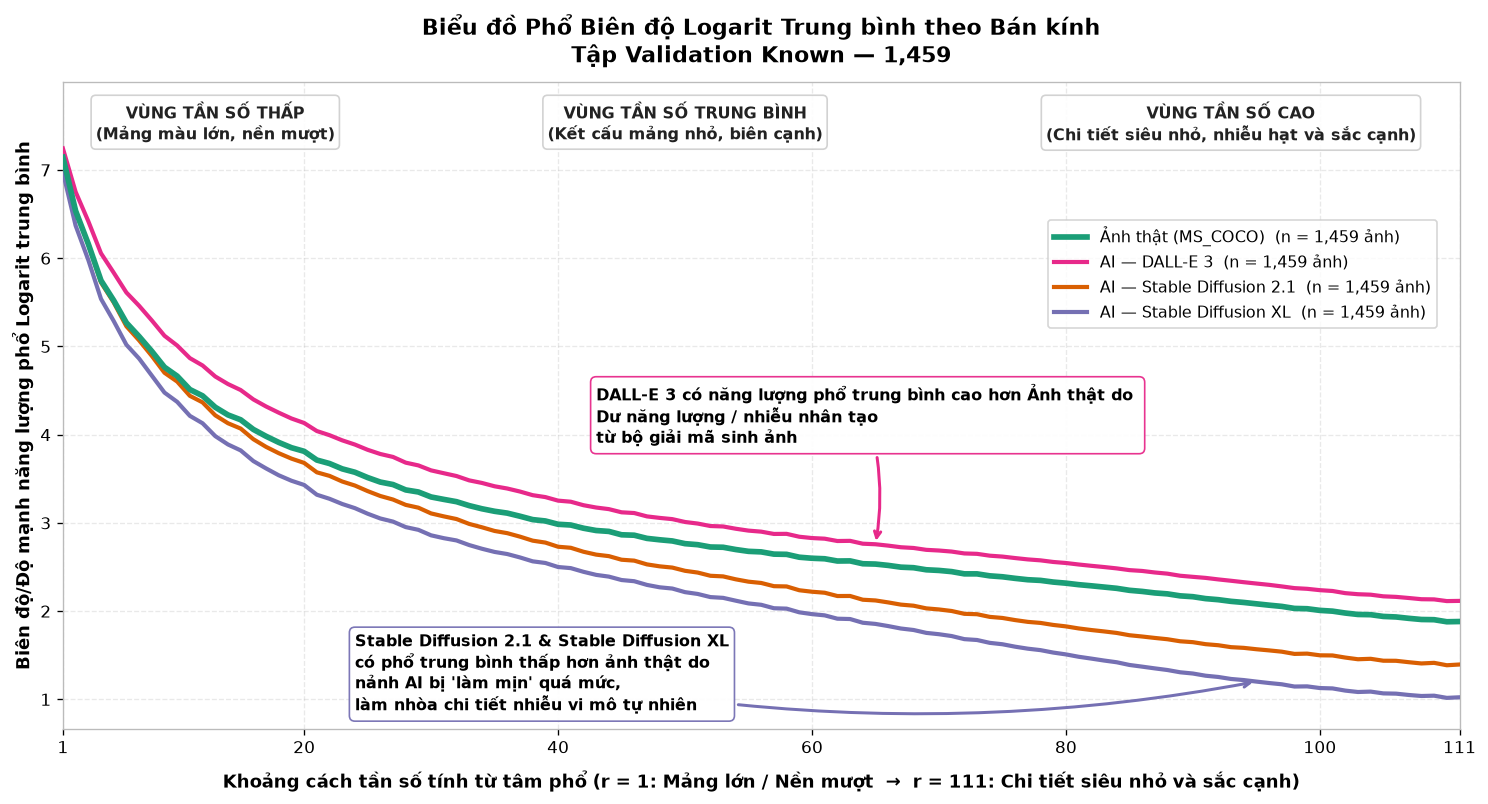

In [5]:
fig, ax = plt.subplots(figsize=(12.5, 6.8))

# Tô nền 3 vùng tần số kèm giải thích đời thường
bands = [
    (1, 25, "#FFFFFF", "VÙNG TẦN SỐ THẤP\n(Mảng màu lớn, nền mượt)"),
    (25, 75, "#FFFFFF", "VÙNG TẦN SỐ TRUNG BÌNH\n(Kết cấu mảng nhỏ, biên cạnh)"),
    (75, 111, "#FFFFFF", "VÙNG TẦN SỐ CAO\n(Chi tiết siêu nhỏ, nhiễu hạt và sắc cạnh)"),
]
for b_start, b_end, b_col, _ in bands:
    ax.axvspan(b_start, b_end, color=b_col, alpha=0.50, zorder=0)

# Vẽ các đường trên cùng 1 đồ thị
linestyles = {
    "MS_COCO": "-",
    "DALL-E_3": "-",
    "Stable_Diffusion_2.1": "-",
    "Stable_Diffusion_XL": "-",
    "Stable_Diffusion_3": "-",
    "Midjourney_V6": "-",
}
for m in MODEL_ORDER:
    lw = 3.4 if m == "MS_COCO" else 2.5
    zorder = 5 if m == "MS_COCO" else 4
    lbl = f"{DISPLAY_NAMES[m]}  (n = {counts_by_model[m]:,} ảnh)"
    ax.plot(
        radii,
        radial_profiles[m],
        label=lbl,
        color=PALETTE[m],
        linewidth=lw,
        linestyle=linestyles.get(m, "-"),
        zorder=zorder,
    )

# Nhãn chú thích 3 vùng tần số đặt gọn ở phía trên
y_max = max(p.max() for p in radial_profiles.values())
y_min = min(p.min() for p in radial_profiles.values())
ax.set_ylim(y_min - 0.35, y_max + 0.75)
y_top_box = y_max + 0.55

for b_start, b_end, _, b_lbl in bands:
    ax.text(
        (b_start + b_end) / 2.0,
        y_top_box,
        b_lbl,
        ha="center",
        va="top",
        fontsize=9.3,
        fontweight="bold",
        color="#222222",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.88, edgecolor="#cccccc"),
    )

# Thêm 2 mũi tên giải thích trực tiếp ngay trên đồ thị (chỉ thẳng vào chỗ khác biệt giữa AI và Real)
r_idx_de3 = 64  # r = 65
ax.annotate(
    "DALL-E 3 có năng lượng phổ trung bình cao hơn Ảnh thật do \nDư năng lượng / nhiễu nhân tạo\ntừ bộ giải mã sinh ảnh",
    xy=(65, radial_profiles["DALL-E_3"][r_idx_de3]),
    xytext=(43, radial_profiles["DALL-E_3"][r_idx_de3] + 1.15),
    arrowprops=dict(arrowstyle="->", color=PALETTE["DALL-E_3"], lw=1.8, connectionstyle="arc3,rad=-0.12"),
    fontsize=9.5,
    fontweight="bold",
    # color=PALETTE["DALL-E_3"],
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor=PALETTE["DALL-E_3"], alpha=0.95),
    zorder=6,
)

r_idx_sd = 94  # r = 95
ax.annotate(
    "Stable Diffusion 2.1 & Stable Diffusion XL\ncó phổ trung bình thấp hơn ảnh thật do\nnảnh AI bị 'làm mịn' quá mức,\nlàm nhòa chi tiết nhiễu vi mô tự nhiên",
    xy=(95, radial_profiles["Stable_Diffusion_XL"][r_idx_sd]),
    xytext=(24, y_min - 0.14),
    arrowprops=dict(arrowstyle="->", color=PALETTE["Stable_Diffusion_XL"], lw=1.8, connectionstyle="arc3,rad=0.10"),
    fontsize=9.5,
    fontweight="bold",
    # color="#4a4480",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor=PALETTE["Stable_Diffusion_XL"], alpha=0.95),
    zorder=6,
)

ax.set_xlim(1, MAX_R)
ax.set_xticks([1, 20, 40, 60, 80, 100, 111])
ax.set_xlabel(
    "Khoảng cách tần số tính từ tâm phổ (r = 1: Mảng lớn / Nền mượt  →  r = 111: Chi tiết siêu nhỏ và sắc cạnh)",
    fontsize=11,
    fontweight="bold",
    labelpad=8,
)
ax.set_ylabel(
    "Biên độ/Độ mạnh năng lượng phổ Logarit trung bình",
    fontsize=11,
    fontweight="bold",
)
ax.set_title(
    f"Biểu đồ Phổ Biên độ Logarit Trung bình theo Bán kính\n"
    f"Tập Validation Known — {n_real:,}",
    fontsize=13,
    fontweight="bold",
    pad=12,
)

ax.legend(
    loc="upper right",
    bbox_to_anchor=(0.99, 0.80),
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc",
    fontsize=9.8,
)

plt.tight_layout()
out_path = OUT_DIR / "fft_1d_radial_all_models.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
print(f"-> Đã lưu biểu đồ tại: {out_path}")
plt.show()

## 4. Bản đồ Phổ 2D FFT Trung bình & Bản đồ Sai khác (`AI − Real`) cho Slide

**Tại sao nên dùng Bản đồ Phổ 2D Trung bình trên 1,459 ảnh cùng chủ đề cho Slide?**
* Trên **1 ảnh đơn lẻ**, các tia sáng của phổ 2D phụ thuộc nhiều vào hướng cạnh của vật thể trong ảnh đó (nhà, chữ viết, cột điện...), nên mắt thường khó tách bạch đâu là cạnh vật thể và đâu là dấu vết AI.
* Khi lấy trung bình phổ 2D trên **cùng 1,459 ảnh gốc/sinh ảnh có chung nội dung mô tả**, mọi đường cạnh ngẫu nhiên tự triệt tiêu, **lộ rõ dấu vân tay thuần túy của Camera thật vs Bộ giải mã AI**:
  1. **Hàng 1 — Phổ 2D Log-Power `log(1 + |F|)` (Khử DC, dùng chung thang màu `magma`):** giữ nguyên độ lớn năng lượng thật để so sánh trực tiếp độ sáng vùng rìa tần số cao.
  2. **Hàng 2 — Bản đồ Sai khác `Δ = Phổ AI − Phổ Ảnh thật` (thang phân kỳ `RdBu_r`):** biến sự khác biệt tinh vi thành màu sắc trực diện (**Đỏ** = AI dư năng lượng/nhiễu cộng hưởng; **Xanh** = AI bị làm mịn, hụt tần số cao).

In [ ]:
from matplotlib.patches import Circle

n_cols = len(MODEL_ORDER)
fig = plt.figure(figsize=(4.4 * n_cols + 1.1, 9.2))
gs = fig.add_gridspec(2, n_cols + 1, width_ratios=[1] * n_cols + [0.06], wspace=0.14, hspace=0.28)

raw_vmin = 0.5
raw_vmax = 5.8

diffs = {m: mean_raw_2d[m] - mean_raw_2d["MS_COCO"] for m in MODEL_ORDER if m != "MS_COCO"}
diff_abs_max = max(float(np.abs(d).max()) for d in diffs.values())
diff_lim = round(min(max(diff_abs_max, 0.8), 1.2), 2)

# ---- HÀNG 1: Phổ 2D Trung bình Log-Power (cùng thang magma) ----
im_raw_ref = None
for j, m in enumerate(MODEL_ORDER):
    ax = fig.add_subplot(gs[0, j])
    im_raw = ax.imshow(mean_raw_2d[m], cmap="magma", vmin=raw_vmin, vmax=raw_vmax)
    if j == 0:
        im_raw_ref = im_raw

    # Vẽ vòng tròn nét đứt mảnh r=75 phân vùng Lõi (Thấp/Trung) vs Vành ngoài (Tần số cao)
    ring = Circle((112, 112), radius=75, fill=False, edgecolor="white", linestyle="--", linewidth=1.1, alpha=0.65)
    ax.add_patch(ring)
    if j == 0:
        ax.text(112, 18, "Tần số Cao (r > 75)", color="white", fontsize=8.5, fontweight="bold", ha="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="black", alpha=0.50, ec="none"))
        ax.text(112, 198, "Ảnh thật chuẩn gốc", color="#7ef5c6", fontsize=8.8, fontweight="bold", ha="center",
                bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.6, ec="#1b9e77", lw=1.0))
        for spine in ax.spines.values():
            spine.set_edgecolor("#1b9e77")
            spine.set_linewidth(2.5)

    mean_val = float(mean_raw_2d[m].mean())
    ax.set_title(f"{DISPLAY_NAMES[m]}\nMean = {mean_val:.2f}", fontsize=10.8, fontweight="bold", pad=8)
    ax.set_xticks([])
    ax.set_yticks([])

cax_raw = fig.add_subplot(gs[0, n_cols])
cbar_raw = fig.colorbar(im_raw_ref, cax=cax_raw)
cbar_raw.set_label("Biên độ Phổ log(1 + |F|)", fontsize=10, fontweight="bold")

# ---- HÀNG 2: Bản đồ Sai khác (AI - Real) ----
im_diff_ref = None
for j, m in enumerate(MODEL_ORDER):
    ax = fig.add_subplot(gs[1, j])
    if m == "MS_COCO":
        ax.set_facecolor("#f8faf9")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor("#1b9e77")
            spine.set_linewidth(2.0)
        guide_txt = (
            "CÁCH ĐỌC BẢN ĐỒ PHỔ 2D\n"
            "────────────────────────\n"
            "• Tâm (112,112): Mảng màu lớn\n"
            "  (Tần số thấp — đã khử DC)\n\n"
            "• Mép ngoài (r > 75): Chi tiết\n"
            "  nhỏ, sợi nét, nhiễu hạt\n\n"
            "• ĐỎ (Δ > 0): AI dư năng lượng\n"
            "  hoặc lộ vân lưới giải mã\n\n"
            "• XANH (Δ < 0): AI bị làm mịn,\n"
            "  mất chi tiết tần số cao"
        )
        ax.text(0.5, 0.5, guide_txt, ha="center", va="center", fontsize=9.2,
                color="#1a1a1a", linespacing=1.35, transform=ax.transAxes)
        ax.set_title("Gốc đối chiếu: Ảnh thật\n(Δ = 0.00)", fontsize=10.8, fontweight="bold", color="#1b9e77", pad=8)
    else:
        d = diffs[m]
        im_diff = ax.imshow(d, cmap="RdBu_r", vmin=-diff_lim, vmax=diff_lim)
        im_diff_ref = im_diff
        ring = Circle((112, 112), radius=75, fill=False, edgecolor="#222222", linestyle="--", linewidth=1.0, alpha=0.55)
        ax.add_patch(ring)

        if m == "DALL-E_3":
            # Khoanh tròn nét đứt vào 2 cụm cộng hưởng đối xứng đặc trưng của DALL-E 3
            for cy, cx in [(58, 41), (166, 183)]:
                ax.add_patch(Circle((cx, cy), radius=22, fill=False, edgecolor="#800026", linestyle="--", linewidth=1.6))
            ax.text(112, 211, f"Dư cao tần + 4 cụm cộng hưởng\n(Max Δ = {d.max():+.2f})", color="#67000d",
                    fontsize=8.3, fontweight="bold", ha="center", va="bottom",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.88, ec="#cb181d"))
        elif m == "Stable_Diffusion_2.1":
            ax.text(112, 211, f"Hụt năng lượng vành cao tần\n(Min Δ = {d.min():+.2f})", color="#08306b",
                    fontsize=8.3, fontweight="bold", ha="center", va="bottom",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.88, ec="#2171b5"))
        elif m == "Stable_Diffusion_XL":
            ax.text(112, 211, f"Làm mịn mạnh vùng cao tần\n(Min Δ = {d.min():+.2f})", color="#08306b",
                    fontsize=8.3, fontweight="bold", ha="center", va="bottom",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.88, ec="#08519c"))

        ax.set_title(f"Sai khác: {DISPLAY_NAMES[m].replace('AI — ', '')} − Ảnh thật", fontsize=10.5, fontweight="bold", pad=8)
        ax.set_xticks([])
        ax.set_yticks([])

cax_diff = fig.add_subplot(gs[1, n_cols])
cbar_diff = fig.colorbar(im_diff_ref, cax=cax_diff)
cbar_diff.set_label("Sai khác Δ = Phổ AI − Phổ Thật", fontsize=10, fontweight="bold")

fig.suptitle(
    f"So sánh Bản đồ Phổ 2D FFT: Ảnh Thật vs Các Bộ Sinh Ảnh AI\n"
    f"(Trung bình trên {n_real:,} bộ ảnh cùng chủ đề — Tập Validation Known | Đã khử thành phần DC)",
    fontsize=13.5,
    fontweight="bold",
    y=1.03,
)

out_2d_slide = OUT_DIR / "fft_2d_mean_and_diff_slide.png"
plt.savefig(out_2d_slide, dpi=300, bbox_inches="tight")
print(f"-> Đã lưu biểu đồ 2D Slide chính tại: {out_2d_slide}")
plt.show()

## 5. Bản đồ Phổ 2D FFT Chuẩn Đầu vào Mạng (`Đã khử DC & Z-Score`)

Hình này giữ đúng quy trình chuẩn hóa **Instance Z-Score** như đầu vào trực tiếp đưa vào nhánh `FFT Residual CNN` (cùng bảng màu `magma` với ảnh trong `predict_single.ipynb`), giúp đối chiếu hình thái phân bố không gian tần số giữa Ảnh thật và các mô hình AI.

In [ ]:
n_cols = len(MODEL_ORDER)
fig = plt.figure(figsize=(4.4 * n_cols + 1.0, 5.2))
gs = fig.add_gridspec(1, n_cols + 1, width_ratios=[1] * n_cols + [0.06], wspace=0.14)

z_vmin, z_vmax = -2.2, 3.8
im_z_ref = None

for j, m in enumerate(MODEL_ORDER):
    ax = fig.add_subplot(gs[0, j])
    im_z = ax.imshow(mean_zscore_2d[m], cmap="magma", vmin=z_vmin, vmax=z_vmax)
    if j == 0:
        im_z_ref = im_z
        for spine in ax.spines.values():
            spine.set_edgecolor("#1b9e77")
            spine.set_linewidth(2.5)
        ax.text(112, 211, "Lan tỏa cân đối, tự nhiên", color="white", fontsize=8.3, fontweight="bold",
                ha="center", va="bottom", bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.6, ec="#1b9e77"))
    elif m == "DALL-E_3":
        for cy, cx in [(58, 41), (166, 183)]:
            ax.add_patch(Circle((cx, cy), radius=20, fill=False, edgecolor="cyan", linestyle="--", linewidth=1.6))
        ax.text(112, 211, "4 cụm cộng hưởng góc chéo", color="cyan", fontsize=8.3, fontweight="bold",
                ha="center", va="bottom", bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.65, ec="cyan"))
    elif m == "Stable_Diffusion_2.1":
        ax.text(112, 211, "Rìa cao tần suy giảm dần", color="#ffd599", fontsize=8.3, fontweight="bold",
                ha="center", va="bottom", bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.6, ec="#d95f02"))
    elif m == "Stable_Diffusion_XL":
        ax.text(112, 211, "Năng lượng bó hẹp về tâm", color="#d0ceff", fontsize=8.3, fontweight="bold",
                ha="center", va="bottom", bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.6, ec="#7570b3"))

    ax.set_title(DISPLAY_NAMES[m], fontsize=10.8, fontweight="bold", pad=8)
    ax.set_xticks([])
    ax.set_yticks([])

cax_z = fig.add_subplot(gs[0, n_cols])
cbar_z = fig.colorbar(im_z_ref, cax=cax_z)
cbar_z.set_label("Z-Score Phổ 2D (Đầu vào CNN)", fontsize=10, fontweight="bold")

fig.suptitle(
    f"Bản đồ Phổ 2D Fourier (FFT) — Đã khử DC & Chuẩn hóa Z-Score (Trung bình {n_real:,} bộ ảnh)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)

out_2d_zscore = OUT_DIR / "fft_2d_zscore_comparison.png"
plt.savefig(out_2d_zscore, dpi=300, bbox_inches="tight")
print(f"-> Đã lưu biểu đồ Z-Score tại: {out_2d_zscore}")
plt.show()

## 6. Minh họa trên 1 Bộ Ảnh Thực tế Cùng Chủ đề (`group_id = 422`)

Đặt trực diện **vùng cắt `224x224` pixel gốc** cạnh **Bản đồ Phổ 2D FFT (`Đã khử DC & Z-Score` và `Log-Power`)** của cùng 1 chủ đề ảnh trong tập Validation để minh họa quy trình biến đổi trực quan trên Slide giới thiệu nhánh FFT.

In [ ]:
SAMPLE_GROUP_ID = 422
sample_models = [m for m in ["MS_COCO", "DALL-E_3", "Stable_Diffusion_2.1", "Stable_Diffusion_XL"] if m in MODEL_ORDER]
sub_df = eval_df[eval_df["group_id"] == SAMPLE_GROUP_ID].set_index("model_name")

fig = plt.figure(figsize=(4.4 * len(sample_models) + 1.0, 9.0))
gs = fig.add_gridspec(2, len(sample_models) + 1, width_ratios=[1] * len(sample_models) + [0.06], wspace=0.14, hspace=0.22)

im_ex_ref = None
for j, m in enumerate(sample_models):
    rel_path = str(sub_df.loc[m, "filepath"]).replace("\\", "/")
    views = common_proc(DATASET_ROOT / rel_path, sample_id=rel_path)
    raw_map = fft_raw_proc(views).squeeze(0).numpy()

    ax_img = fig.add_subplot(gs[0, j])
    ax_img.imshow(views["view_native"])
    ax_img.set_title(f"{DISPLAY_NAMES[m]}\n(Vùng cắt Native 224x224)", fontsize=10.2, fontweight="bold", pad=6)
    ax_img.set_xticks([])
    ax_img.set_yticks([])

    ax_fft = fig.add_subplot(gs[1, j])
    im_ex = ax_fft.imshow(raw_map, cmap="magma", vmin=0.0, vmax=6.5)
    if j == 0:
        im_ex_ref = im_ex
    ax_fft.set_title(f"Bản đồ Phổ 2D FFT (Khử DC)\nMean năng lượng = {raw_map.mean():.2f}", fontsize=10.0, fontweight="bold", pad=6)
    ax_fft.set_xticks([])
    ax_fft.set_yticks([])

cax_ex_top = fig.add_subplot(gs[0, len(sample_models)])
cax_ex_top.axis("off")

cax_ex = fig.add_subplot(gs[1, len(sample_models)])
cbar_ex = fig.colorbar(im_ex_ref, cax=cax_ex)
cbar_ex.set_label("Biên độ Phổ log(1 + |F|)", fontsize=10, fontweight="bold")

caption_txt = str(sub_df.iloc[0]["caption"])
fig.suptitle(
    f"Ví dụ Trực quan cùng Chủ đề (Group {SAMPLE_GROUP_ID}: \"{caption_txt}\")\n"
    f"Vùng cắt Native 224x224 & Bản đồ Phổ 2D FFT tương ứng",
    fontsize=12.5,
    fontweight="bold",
    y=1.03,
)

out_2d_pair = OUT_DIR / "fft_2d_single_group_example.png"
plt.savefig(out_2d_pair, dpi=300, bbox_inches="tight")
print(f"-> Đã lưu ví dụ cùng chủ đề tại: {out_2d_pair}")
plt.show()